# Exploratory Data Analysis

The **Lidl purchasing group** wants to expand our candy offering. These are store brand candies that we sell along the brand offerings. The idea is to create a brand-new product. The type of the brand new product (gummies, cookie-based etc.) should be decided via a data-driven approach. In this notebook the collected market research data will be analysed and prepared for ingestion by predictive models.

The **[data set](https://github.com/fivethirtyeight/data/tree/master/candy-power-ranking)** is provided by FiveThirtyEight under the Creative Commons Attribution 4.0 International license.

The dataset contains the following columns:

- `chocolate` - Does it contain chocolate?
- `fruity` - Is it fruit flavored?
- `caramel` - Is there caramel in candy?
- `peanutalmondy` - Does it contain peanuts, peanut butter or almonds?
- `nougat` - Does it contain nougat?
- `crispedricewafer` - Does it contain crisped rice, wafers, or a cookie component?
- `hard` - Is it a hard candy?
- `bar` - Is it a candy bar?
- `pluribus` - Is it one of many candies in a bag or box?
- `sugarpercent` - The percentile of sugar it falls under within the data set.
- `pricepercent` - The unit price percentile compared to the rest of the set.
- `winpercent` - The overall win percentage according to 269,000 matchups.

The columns except the last 3 and the first columns contain binary variables, where `1` means *yes* and `0` means *no*.


In [ ]:
# Importing dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from pathlib import Path


In [2]:
# downloading the dataset if it is non-existent

# locating the data folder
BASE_DIR = Path("EDA.ipynb").resolve().parents[0]
DATA_DIR = BASE_DIR / "data" 

# Create data folder if it doesn't exist
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Fetching the data from the provided github repo if it doesn't exists
if Path(DATA_DIR / "candy-data.csv").is_file():
    print("candy-data.csv already exists... Skipping download")
else:
    print("Downloading candy-data.csv")
    url = "https://raw.githubusercontent.com/fivethirtyeight/data/refs/heads/master/candy-power-ranking/candy-data.csv"
    request = requests.get(url)
    with open(DATA_DIR / "candy-data.csv", "wb") as f:
        f.write(request.content)

## 1. Loading and analysing the data

In [3]:
candy_df = pd.read_csv(DATA_DIR / "candy-data.csv")
candy_df

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
0,100 Grand,1,0,1,0,0,1,0,1,0,0.732,0.860,66.971725
1,3 Musketeers,1,0,0,0,1,0,0,1,0,0.604,0.511,67.602936
2,One dime,0,0,0,0,0,0,0,0,0,0.011,0.116,32.261086
3,One quarter,0,0,0,0,0,0,0,0,0,0.011,0.511,46.116505
4,Air Heads,0,1,0,0,0,0,0,0,0,0.906,0.511,52.341465
...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,Twizzlers,0,1,0,0,0,0,0,0,0,0.220,0.116,45.466282
81,Warheads,0,1,0,0,0,0,1,0,0,0.093,0.116,39.011898
82,Welch's Fruit Snacks,0,1,0,0,0,0,0,0,1,0.313,0.313,44.375519
83,Werther's Original Caramel,0,0,1,0,0,0,1,0,0,0.186,0.267,41.904308


In [4]:
candy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   competitorname    85 non-null     object 
 1   chocolate         85 non-null     int64  
 2   fruity            85 non-null     int64  
 3   caramel           85 non-null     int64  
 4   peanutyalmondy    85 non-null     int64  
 5   nougat            85 non-null     int64  
 6   crispedricewafer  85 non-null     int64  
 7   hard              85 non-null     int64  
 8   bar               85 non-null     int64  
 9   pluribus          85 non-null     int64  
 10  sugarpercent      85 non-null     float64
 11  pricepercent      85 non-null     float64
 12  winpercent        85 non-null     float64
dtypes: float64(3), int64(9), object(1)
memory usage: 8.8+ KB


It seems that every row is complete and we don't have `Nan` values in any columns. So no cleaning and handling Nan values are needed.

Now I will check if all of the rows are related to unique products and there are no duplications. If the length of the unique list equals to the total number of rows, then we can assume that each row represents a unique product.

In [5]:
len(candy_df['competitorname'].unique())

85

### Plotting the occurance of each feature

First I will start with plotting how often each characteristic occurs within the dataset. That will help me to familiarize myself with the dataset.

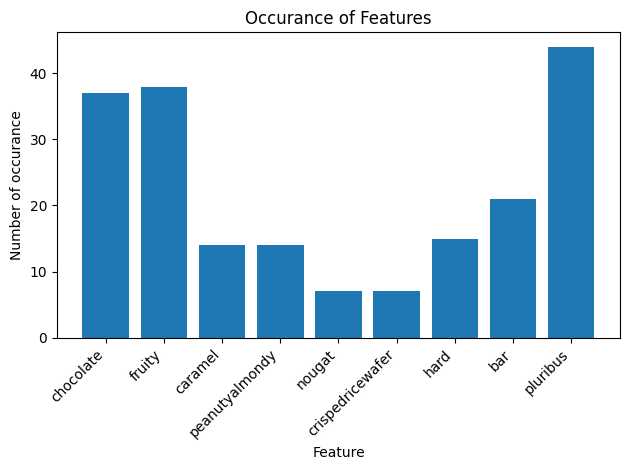

In [6]:
# columns to plot
columns = ['chocolate', 'fruity', 'caramel', 'peanutyalmondy', 'nougat', 'crispedricewafer', 'hard', 'bar', 'pluribus']

# we have binary data so taking the sum of these columns will give the exact count
counts = candy_df[columns].sum()
counts_val = counts.values # creating a list of values

# plotting
plt.bar(columns, counts_val)
plt.title('Occurance of Features')
plt.xlabel('Feature')
plt.ylabel('Number of occurance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


It is quite visible that the most frequently used ingredients are `chocholate` and `fruity` flavors. It is also visible that at least half of the samples are `pluribus`, so comes in bag or box. 

In [7]:
# Checking if all of the rows are related to unique products
len(candy_df['competitorname'].unique())

85

### 1.1 Cross-Analysing features of the sweets

I would like to establish certain product categories. To do that, I will try to understand the relationship between product characteristics, rather than looking at each characteristics independently.

**Feature Correlation Analysis**: The first thing I will do is to check the correlation between characteristics. A Strong positive correlation means the two features frequently occur together. Strong negative means that if the feature is present, the other tend to be absent.

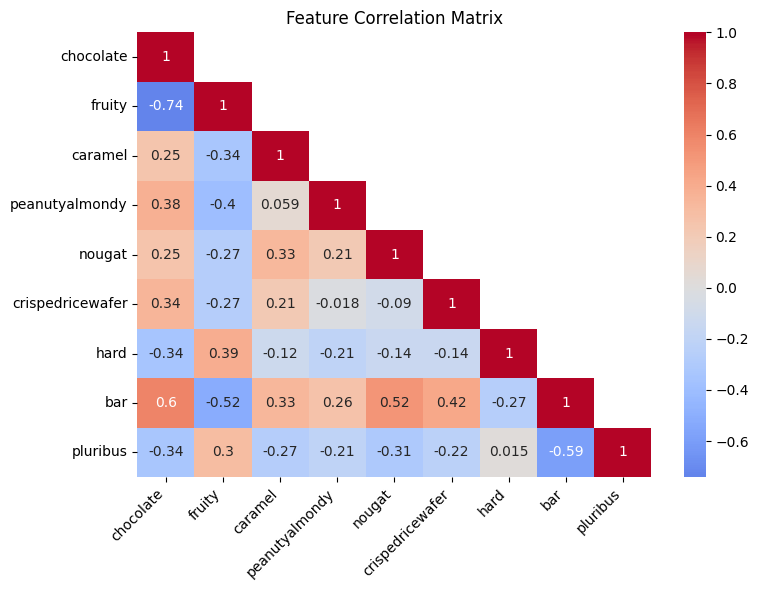

In [8]:
# I will check the following features
features = ['chocolate', 'fruity', 'caramel','peanutyalmondy', 'nougat','crispedricewafer', 'hard', 'bar','pluribus']

corr = candy_df[features].corr()

# Mask the upper triangle so symmetric pairs aren't repeated
mask = np.triu(np.ones_like(corr, dtype=bool), k=1) # k=1 leaves the diagonal untouched

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    mask = mask,
    annot = True,
    cmap = 'coolwarm',
    center = 0
)
plt.title('Feature Correlation Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interesting**. We have a not so strong correlation between `chocolate` and `bar`, that means that chocolate products have a slight tendency to be bars. Also we have a somewhat strong negative correlation between `fruity` and `chocolate`, that indicates that fruity sweets usually do not contain chocolate. But besides these nothing very strong and conclusive.

I still have a feeling, that certain characteristics have the tendency to occur together, so I will check the **Conditional probability** of the features. 

In [9]:
# I would like to do a conditional probability for every possible permutation. 
from itertools import permutations

df = candy_df.copy()

# checking the same features
features = ['chocolate', 'fruity', 'caramel','peanutyalmondy', 'nougat','crispedricewafer', 'hard', 'bar','pluribus']

results = []
for a, b in permutations(features, 2):
    p = df[df[a] == 1][b].mean()

    results.append({
        'Feature A': a,
        'Feature B': b,
        'P(B|A)': p
    })

conditional_df = pd.DataFrame(results)

conditional_df.sort_values('P(B|A)', ascending=False, inplace=True)

conditional_df

,Feature A,Feature B,P(B|A)
40,crispedricewafer,chocolate,1.000000
38,nougat,bar,1.000000
56,bar,chocolate,0.952381
49,hard,fruity,0.866667
24,peanutyalmondy,chocolate,0.857143
...,...,...,...
57,bar,fruity,0.000000
63,bar,pluribus,0.000000
62,bar,hard,0.000000
68,pluribus,nougat,0.000000


That looks promising. To make sure that these features aren't walking hand in hand by chance I will examine their association strength. 
I will calculate the lift/support of their association strength.

In [10]:
# Calculate the baseline probability for all the features
baseline_probs = df[features].mean()

# Map P(B) onto conditional_df based on 'Feature B'
conditional_df['P(B)'] = conditional_df['Feature B'].map(baseline_probs)

# Calculate Lift = P(B|A) / P(B)
conditional_df['Lift'] = conditional_df['P(B|A)'] / conditional_df['P(B)']

# Sort by highest Lift to see the strongest associations
conditional_df.sort_values('Lift', ascending=False, inplace=True)

conditional_df

,Feature A,Feature B,P(B|A),P(B),Lift
38,nougat,bar,1.000000,0.247059,4.047619
60,bar,nougat,0.333333,0.082353,4.047619
34,nougat,caramel,0.571429,0.164706,3.469388
46,crispedricewafer,bar,0.857143,0.247059,3.469388
61,bar,crispedricewafer,0.285714,0.082353,3.469388
...,...,...,...,...,...
57,bar,fruity,0.000000,0.447059,0.000000
63,bar,pluribus,0.000000,0.517647,0.000000
62,bar,hard,0.000000,0.176471,0.000000
68,pluribus,nougat,0.000000,0.082353,0.000000


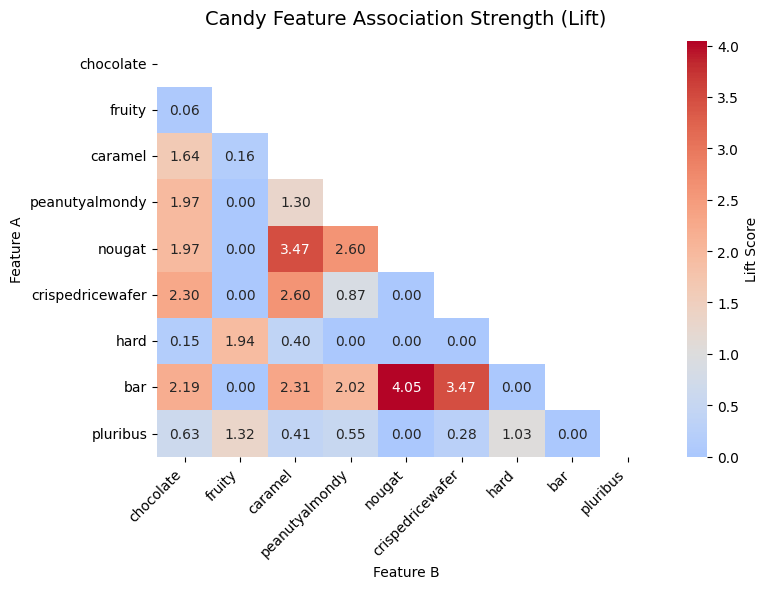

In [11]:
# Plotting the lift

# Reshape conditional_df into a square matrix
lift_matrix = conditional_df.pivot(
    index='Feature A', columns='Feature B', values='Lift'
)

# Reorder rows and columns to match your original feature list
lift_matrix = lift_matrix.reindex(index=features, columns=features)

# Masking the upper triangle so symmetric pairs aren't repeated
mask = np.triu(np.ones_like(lift_matrix, dtype=bool))

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    lift_matrix,
    mask=mask,
    annot=True,  # Show exact lift values in each cell
    fmt='.2f',  
    cmap='coolwarm',  
    center=1.0,  # independent values
    vmin=0,  # fix minimum at 0
    cbar_kws={'label': 'Lift Score'},
)

plt.title('Candy Feature Association Strength (Lift)', fontsize=14, pad=12)
plt.xlabel('Feature B')
plt.ylabel('Feature A')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

- Lift > 1: Means positive association.
- Lift = 1: Approximately independent features.
- Lift < 1: Negative association.

It seems there are quite a lot of features where simultaneous occurance is not by chance. Just to double check I did not make a mistake I will check myself by looking at feature co-occurance for the highest amounts in the heatmap

In [12]:
# Nougat and Caramel occurance together
table1 = pd.crosstab(candy_df['nougat'], candy_df['caramel'], margins=True)
table1

caramel,0,1,All
nougat,,,
0,68,10,78
1,3,4,7
All,71,14,85


From the table above we can calculate the lift to check if our numbers are correct. We calculate the lift by `Lift(Nougat, Caramel) = P(Nougat=1, Caramel=1) / P(Nougat=1) x P(Caramel=1)`.

In our case:
- P(Nougat=1) = 7/85
- P(Caramel=1) = 14/85
- P(Nougat=1, Caramel=1) = 4/85


In [13]:
Lift = (4/85) / ((7/85) * (14/85))
print(round(Lift,2))

3.47


It seems to be matching. Just one more check and if that works, then I will assume that our association strengths are correct. 

In [14]:
# Nougat and Caramel
table1 = pd.crosstab(candy_df['nougat'], candy_df['bar'], margins=True)
table1

bar,0,1,All
nougat,,,
0,64,14,78
1,0,7,7
All,64,21,85


In [15]:
Lift = (7/85) / ((21/85) * (7/85))
print(round(Lift, 2))

4.05


So our scores are good. It means that for example **nougat** and **caramel** have **3.47** times higher chance of occuring together than if they were independent. 

### 1.2 Cross-Analysing features against business variables

Besides the "flavor" features we have:

* sugarpercent
* pricepercent
* winpercent

I will examine how certain product features relate to consumer popularity, sugar content and price positioning.

The first thing I will check is if there is any correlation between sugarpercent, pricepercent and winpercent. 


In [16]:
business_features = ['sugarpercent', 'pricepercent', 'winpercent']

b_corr = candy_df[business_features].corr()
b_corr

,sugarpercent,pricepercent,winpercent
sugarpercent,1.000000,0.329706,0.229151
pricepercent,0.329706,1.000000,0.345325
winpercent,0.229151,0.345325,1.000000


Basically all the correlations are very weak. It tells that `sugarpercent` and `pricepercent`has negligible effect on `winpercent`. 

### Individual Product Characteristic Association Strength

Now I will check which product characteristics are associated with higher **winpercent** amount.

To do this I will perform `Welch's independent samples T-test`, instead of classic `Student T-test` because I have very unequal sample sizes for each category


In [17]:

features = ['chocolate', 'fruity','caramel','peanutyalmondy','nougat','crispedricewafer','hard','bar','pluribus']

from utils.StatTest import WelchT

welch_results = WelchT.welch_t_test(features, param='winpercent', df=candy_df)
welch_df = pd.DataFrame(welch_results)

# Rounding results
welch_df['P-value'] = round(welch_df['P-value'], 4)
welch_df['T-statistic'] = round(welch_df['T-statistic'], 2)
welch_df = welch_df.sort_values(by="P-value")
welch_df

,Feature,N with feature,N without feature,Mean with feature,Mean without feature,Difference,T-statistic,P-value,Conf Interval low,Conf Interval high
0,chocolate,37,48,60.92,42.14,18.78,7.30,0.0000,13.65,23.91
7,bar,21,64,61.30,46.71,14.58,4.87,0.0000,8.54,20.62
6,hard,15,70,40.51,52.42,-11.91,-4.62,0.0000,-17.10,-6.72
1,fruity,38,47,44.12,55.33,-11.21,-3.92,0.0002,-16.89,-5.52
3,peanutyalmondy,14,71,63.70,47.68,16.02,3.45,0.0032,6.20,25.84
5,crispedricewafer,7,78,66.17,48.89,17.28,3.96,0.0041,7.23,27.32
8,pluribus,44,41,46.82,54.07,-7.24,-2.31,0.0232,-13.47,-1.01
2,caramel,14,71,57.35,48.93,8.42,1.81,0.0873,-1.37,18.20
4,nougat,7,78,60.05,49.44,10.61,1.94,0.0927,-2.26,23.48


A positive `Difference` value means, that feature have higher average `winpercent`, a negative value means the opposite. 

At the conventional `5%` significance level, seven features are **statistically significant** based on the **p-values**:
- Chocolate, wafer, peanut/almond and bar are positively associated with popularity.
- Fruity, hard and pluribus are negatively associated with popularity.
- Caramel and nougat do not show statistically significant differences in this analysis.
  
Chocolate is the strongest finding. Sweets containing chocolate have an average winpercent of 60.92, compared with 42.14 for candies without chocolate. That is a difference of 18.78 percentage points.

Wafer and peanut/almond also look promising. Their average differences are +17.28 and +16.02 percentage points, respectively. However, wafer has only seven observations, so its result should be interpreted with some caution.

I will plot the results via a Forest Plot. 

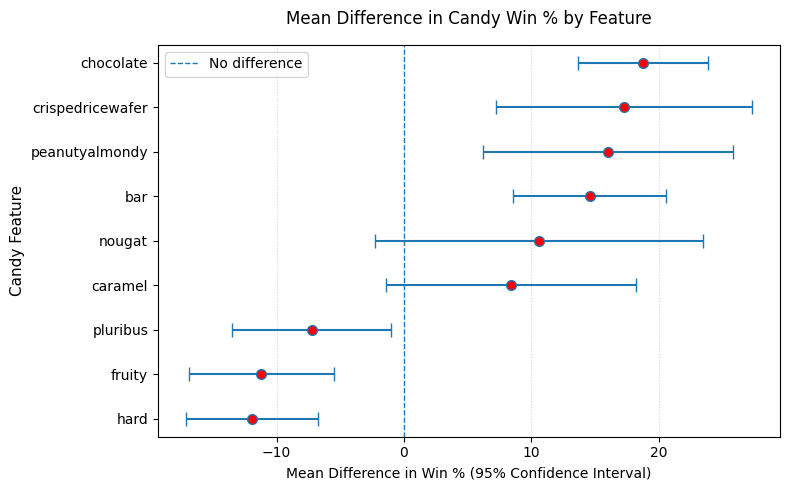

In [18]:
#plot_df is the copy of welch_results
plot_df = welch_df.copy()

# Sort features by mean difference
plot_df = plot_df.sort_values('Difference')

# Create forest plot
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate confidence interval widths
lower_error = plot_df['Difference'] - plot_df['Conf Interval low']
upper_error = plot_df['Conf Interval high'] - plot_df['Difference']

# Plot mean differences and confidence intervals
ax.errorbar(
    plot_df['Difference'],
    plot_df['Feature'],
    xerr=[lower_error, upper_error],
    fmt='o',
    markerfacecolor='red',
    capsize=5,
    markersize=7,
    linewidth=1.5
)

# Add reference line at zero
ax.axvline(
    x=0,
    linestyle='--',
    linewidth=1,
    label='No difference'
)

# Add labels and title
ax.set_title(
    'Mean Difference in Candy Win % by Feature',
    fontsize=12,
    pad=15
)

ax.set_xlabel(
    'Mean Difference in Win % (95% Confidence Interval)',
    fontsize=10
)

ax.set_ylabel('Candy Feature', fontsize=11)

ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

The vertical reference line at zero makes it easy to see whether a confidence interval crosses zero (indicating that the difference is not statistically significant at the 5% level)

The analysis above shows which individual features are associated the most with higher **winpercent**.

Although, I'd like to see, which product categories have overall bigger consumer popularity. In order to do that I will create `Clusters` based on the grouping of individual components.

### 1.3 Creating clusters from the dataset

For creating the clusters I will perform the following steps:
1. Calculating the **Jaccard distance matrix**: Measure how alike data objects are. It measures similarity between two sets. I will use this because it utilizes binary vectors and our data is binary.
2. Performing **Hierarchical clustering**: This method will create the clusters. It is good because we have small dataset and Jaccard distance can be used for the clustering.
3. Cut the hierarchical-tree into n clusters. I will try out several cluster amounts.
4. Calculate the shilouette score to evaluate the clustering

In [19]:

# Selecting the features that should be considered while creating the clusters
# The aim is to determine what flavors consumers like, therefore the packaging in this case is not very relevant, maybe it would just complicate clustering
# Therefore pluribus will be excluded
features = [
    'chocolate',
    'fruity',
    'caramel',
    'peanutyalmondy',
    'nougat',
    'crispedricewafer',
    'hard',
    'bar'
]

# Extract binary features into matrix X
X = df[features].to_numpy(dtype=int)

print(X.shape)

(85, 8)


### Perform Hierarchical Clustering

The hierarchical clustering will be conducted with SciPy's `linkage()` method.
I will examine 3 methods within linkage and check which one gives the best silhouette score. 

* **Average method**: It calculates the average distance between all pairs of observations across two clusters.
* **Single method**: Uses the minimum distance between observations in two clusters.
* **Complete method**: Uses the maximum distance between observations in two clusters.

I will check a couple of clustering splits, and check, which gives the best silhouette score

In [20]:
from utils.ClusterAnalysis import HierarchicalCluster

# Calculating the Jaccard Distance
D = HierarchicalCluster.jaccard_distance(X)

# dictionary for the methods
methods = {"Average Method": "average", "Single Method": "single", "Complete Method": "complete"}

results = []
for name, method in methods.items():
    for k in range(2, 9): # Trying out several splits between 2 and 8
        labels = HierarchicalCluster.k_split_cluster(X, method=method, n_clusters = k)
        score = HierarchicalCluster.silhouette_score(D, labels)

        results.append((name, k, score))
        
for name, k, score in results:
    print(f" Method: {name}, Clusters: {k}, Silhouette score: {score:.4f}")

 Method: Average Method, Clusters: 2, Silhouette score: 0.3152
 Method: Average Method, Clusters: 3, Silhouette score: 0.5533
 Method: Average Method, Clusters: 4, Silhouette score: 0.5543
 Method: Average Method, Clusters: 5, Silhouette score: 0.5305
 Method: Average Method, Clusters: 6, Silhouette score: 0.5232
 Method: Average Method, Clusters: 7, Silhouette score: 0.4953
 Method: Average Method, Clusters: 8, Silhouette score: 0.5375
 Method: Single Method, Clusters: 2, Silhouette score: 0.3152
 Method: Single Method, Clusters: 3, Silhouette score: 0.2156
 Method: Single Method, Clusters: 4, Silhouette score: 0.1877
 Method: Single Method, Clusters: 5, Silhouette score: 0.2175
 Method: Single Method, Clusters: 6, Silhouette score: 0.6250
 Method: Single Method, Clusters: 7, Silhouette score: 0.6345
 Method: Single Method, Clusters: 8, Silhouette score: 0.6666
 Method: Complete Method, Clusters: 2, Silhouette score: 0.4511
 Method: Complete Method, Clusters: 3, Silhouette score: 0.40

In [21]:
# Cut hierarchical tree into 8 clusters and applying single method
labels = HierarchicalCluster.k_split_cluster(X, method='single', n_clusters =8)
# Check labels
labels

array([0, 0, 1, 1, 2, 0, 0, 0, 1, 3, 0, 2, 2, 2, 4, 2, 4, 4, 2, 1, 2, 2,
       0, 0, 0, 0, 4, 0, 0, 2, 4, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 4, 0, 0,
       2, 2, 0, 0, 1, 4, 2, 0, 0, 0, 0, 4, 0, 5, 4, 0, 2, 2, 0, 4, 0, 0,
       2, 2, 2, 4, 6, 6, 2, 2, 4, 0, 0, 0, 2, 0, 2, 4, 2, 7, 0])

In [22]:
for cluster in np.unique(labels):

    cluster_products = X[labels == cluster]

    profile = cluster_products.mean(axis=0)

    print(f"\nCluster {cluster}")
    print("Products:", len(cluster_products))

    for feature, value in zip(features, profile):
        print(f"{feature}: {value:.2f}")


Cluster 0
Products: 38
chocolate: 0.95
fruity: 0.00
caramel: 0.26
peanutyalmondy: 0.37
nougat: 0.18
crispedricewafer: 0.18
hard: 0.00
bar: 0.55

Cluster 1
Products: 5
chocolate: 0.00
fruity: 0.00
caramel: 0.00
peanutyalmondy: 0.00
nougat: 0.00
crispedricewafer: 0.00
hard: 0.00
bar: 0.00

Cluster 2
Products: 24
chocolate: 0.00
fruity: 1.00
caramel: 0.00
peanutyalmondy: 0.00
nougat: 0.00
crispedricewafer: 0.00
hard: 0.00
bar: 0.00

Cluster 3
Products: 1
chocolate: 0.00
fruity: 1.00
caramel: 1.00
peanutyalmondy: 0.00
nougat: 0.00
crispedricewafer: 0.00
hard: 0.00
bar: 0.00

Cluster 4
Products: 13
chocolate: 0.08
fruity: 1.00
caramel: 0.00
peanutyalmondy: 0.00
nougat: 0.00
crispedricewafer: 0.00
hard: 1.00
bar: 0.00

Cluster 5
Products: 1
chocolate: 0.00
fruity: 0.00
caramel: 0.00
peanutyalmondy: 0.00
nougat: 0.00
crispedricewafer: 0.00
hard: 1.00
bar: 0.00

Cluster 6
Products: 2
chocolate: 0.00
fruity: 0.00
caramel: 1.00
peanutyalmondy: 0.00
nougat: 0.00
crispedricewafer: 0.00
hard: 0.00

Now I will name the Clusters and assign them to the candy_df Dataframe.

In [23]:
cluster_names = {
    0: "Chocolate-based Sweets",
    1: "Other Soft",
    2: "Fruity Gummies",
    3: "Soft Fruity Caramel",
    4: "Fruity Hard Candy",
    5: "Other Hard",
    6: "Soft Caramel",
    7: "Hard Caramel"
}

candy_df2 = candy_df.copy()

candy_df2['cluster'] = labels

candy_df2['category'] = candy_df2['cluster'].map(cluster_names)

candy_df2

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent,cluster,category
0,100 Grand,1,0,1,0,0,1,0,1,0,0.732,0.860,66.971725,0,Chocolate-based Sweets
1,3 Musketeers,1,0,0,0,1,0,0,1,0,0.604,0.511,67.602936,0,Chocolate-based Sweets
2,One dime,0,0,0,0,0,0,0,0,0,0.011,0.116,32.261086,1,Other Soft
3,One quarter,0,0,0,0,0,0,0,0,0,0.011,0.511,46.116505,1,Other Soft
4,Air Heads,0,1,0,0,0,0,0,0,0,0.906,0.511,52.341465,2,Fruity Gummies
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,Twizzlers,0,1,0,0,0,0,0,0,0,0.220,0.116,45.466282,2,Fruity Gummies
81,Warheads,0,1,0,0,0,0,1,0,0,0.093,0.116,39.011898,4,Fruity Hard Candy
82,Welch's Fruit Snacks,0,1,0,0,0,0,0,0,1,0.313,0.313,44.375519,2,Fruity Gummies
83,Werther's Original Caramel,0,0,1,0,0,0,1,0,0,0.186,0.267,41.904308,7,Hard Caramel


### 1.4 Analysing the clusters

To establish, which category should be suggested. I will check the average `winpercent` by category

In [24]:
win_per_category = candy_df2[['category', 'winpercent', 'sugarpercent', 'pricepercent']].copy()

result = (
    win_per_category.groupby('category').agg(
        avg_winpercent = ('winpercent', 'mean'),
        avg_sugarpercent = ('sugarpercent', 'mean'),
        avg_pricepercent = ('pricepercent', 'mean')
    ).reset_index()
)

result['avg_winpercent'] = round(result['avg_winpercent'], 2)
result['avg_sugarpercent'] = round(result['avg_sugarpercent'], 2)
result['avg_pricepercent'] = round(result['avg_pricepercent'], 2)
result

,category,avg_winpercent,avg_sugarpercent,avg_pricepercent
0,Chocolate-based Sweets,59.86,0.50,0.64
1,Fruity Gummies,46.08,0.42,0.33
2,Fruity Hard Candy,41.23,0.55,0.34
3,Hard Caramel,41.90,0.19,0.27
4,Other Hard,29.70,0.73,0.07
5,Other Soft,37.65,0.30,0.29
6,Soft Caramel,32.83,0.69,0.55
7,Soft Fruity Caramel,34.52,0.60,0.32


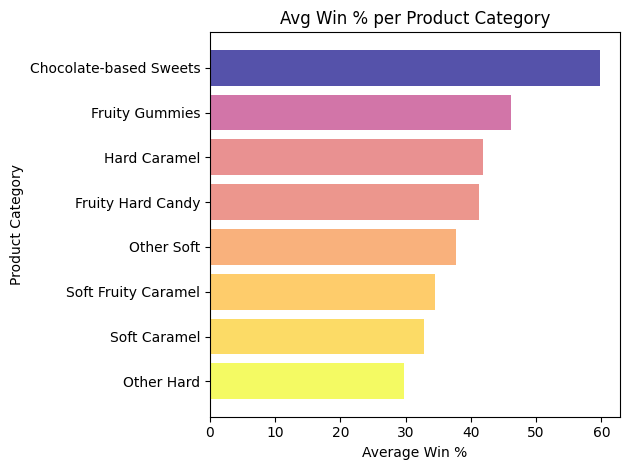

In [25]:
# Sort ascending so the largest value sits at the top of the y-axis
result_sorted = result.sort_values(by='avg_winpercent', ascending=True)

# Generate gradient colors based on the sorted values
norm = plt.Normalize(result_sorted['avg_winpercent'].min(), result_sorted['avg_winpercent'].max())
colors = plt.cm.plasma_r(norm(result_sorted['avg_winpercent'])) 

# plotting
plt.barh(result_sorted['category'], result_sorted['avg_winpercent'], color=colors, alpha=0.7)
plt.title('Avg Win % per Product Category')
plt.xlabel('Average Win %')
plt.ylabel('Product Category')
plt.tight_layout()
plt.show()

Chocolate-based Sweets seems to have the highest winpercent. But that category does not contain only Chocolate. I will explore the effect of different combinations of features within Chocolate-base Sweets. 

Based on **Chocolate-based Sweets** category the following flavors/characteristics should be examined: *chocolate*, *caramel*, *peanutyalmonday*, *nougat*, *crispedricewafer*


In [26]:
from itertools import combinations

features = ['chocolate', 'caramel','peanutyalmondy','nougat','crispedricewafer']

# helper function to return all the combinations of the features
def all_features_combo(features):
    combo = []
    for n in range(1, len(features) + 1):
        combo += [list(i) for i in combinations(features, n)]
    return combo
        
def calc_winpercent(features):

    combinations = all_features_combo(features)
    
    feature_analysis = []
    for c in combinations:

        
        with_feature = candy_df[candy_df[c].eq(1).all(axis=1)]['winpercent'].mean()
        count_feature = candy_df[candy_df[c].eq(1).all(axis=1)]['winpercent'].count()
        
        feature_analysis.append({
            'Feature list': c,
            'Count': count_feature,
            'Win %': with_feature
        })
    
    df = pd.DataFrame(feature_analysis)
    # sorting based on win %
    combo_winpercent = df.sort_values('Win %', ascending=False)
    combo_winpercent['Win %'] = round(combo_winpercent['Win %'], 2)
    
    # dropping combinations which are not present in the dataset
    combo_winpercent.dropna(inplace=True)
    
    # resetting the index without creating additional index column
    combo_df = combo_winpercent.reset_index(drop=True)
    
    return combo_df


df = calc_winpercent(features)
df

,Feature list,Count,Win %
0,"[caramel, crispedricewafer]",3,69.38
1,"[chocolate, caramel, crispedricewafer]",3,69.38
2,"[chocolate, peanutyalmondy]",12,68.50
3,"[caramel, nougat]",4,66.87
4,"[chocolate, caramel, nougat]",4,66.87
5,"[chocolate, peanutyalmondy, nougat]",2,66.79
6,"[caramel, peanutyalmondy, nougat]",2,66.79
7,"[chocolate, caramel, peanutyalmondy, nougat]",2,66.79
8,[crispedricewafer],7,66.17
9,"[chocolate, crispedricewafer]",7,66.17


It is promising but based on `Win %` numbers, there are combinations which are subsets of each other. Therefore I will only keep one from each `Win %`. The one which has the longest list of features

In [27]:
def keep_longest_combinations(df):
    df = df.copy()
    df['Feature count'] = df['Feature list'].apply(len)

    df = df.loc[df.groupby('Win %')['Feature count'].idxmax()]
    df = df.sort_values('Win %', ascending=False)
    
    return df.drop(columns='Feature count').reset_index(drop=True)

cleared_combo_df = keep_longest_combinations(df)
cleared_combo_df

,Feature list,Count,Win %
0,"[chocolate, caramel, crispedricewafer]",3,69.38
1,"[chocolate, peanutyalmondy]",12,68.50
2,"[chocolate, caramel, nougat]",4,66.87
3,"[chocolate, caramel, peanutyalmondy, nougat]",2,66.79
4,"[chocolate, crispedricewafer]",7,66.17
5,"[chocolate, caramel]",10,66.08
6,"[chocolate, caramel, peanutyalmondy]",3,64.37
7,[peanutyalmondy],14,63.70
8,"[chocolate, nougat]",6,62.34
9,[chocolate],37,60.92


### Plotting the results with Bubble Chart

In [28]:
import plotly.express as px

fig = px.scatter(
    cleared_combo_df,
    x="Count",
    y="Win %",
    size="Count",
    size_max=55,
    color="Win %",
    hover_name="Feature list",
    title="Ingredient Combinations vs. Consumer Preference"
)

# Remove labels from every bubble
fig.update_traces(
    text=None,
    mode="markers",
    marker=dict(
        opacity=0.8,
        line=dict(width=1, color="white")
    )
)

# Add selective annotations
highlighted = [
    ("Chocolate + Caramel + Crisped Rice", 3, 69.38),
    ("Chocolate + nuts", 12, 68.50),
    ("Chocolate", 37, 60.92),
    ("Peanut/Almond", 14, 63.70)
]

for label, x, y in highlighted:
    fig.add_annotation(
        x=x,
        y=y,
        text=f"<b>{label}</b>",
        showarrow=False,
        xanchor="center",
        yanchor="bottom",
        yshift=40,
        font=dict(size=14, color="#26364A")
    )

fig.update_layout(
    template="plotly_white",
    height=550,
    width=1000,
    title=dict(
        text="Ingredient Combinations vs. Consumer Preference",
        font=dict(size=20)
    ),
    font=dict(
        family="Arial",
        size=16,
        color="#344054"
    ),
    xaxis=dict(
        title="Number of Products",
        showgrid=True,
        gridcolor="#EAECEF",
        zeroline=False
    ),
    yaxis=dict(
        title="Average Win %",
        range=[55, 72],
        showgrid=True,
        gridcolor="#EAECEF",
        zeroline=False
    ),
    showlegend=False
)


`Chocolate + Caramel + Crisped Rice` combination seems to have the highest number of Win %. Although the sample size is very small (3), therefore it cannot be considered as very reliable. `Chocolate + Nuts` combination seems like a better choice overall.

There are several promising contenders here. To check which ingredient(s) are actually driving **winpercent** growth, I will apply `Multiple Linear Regression`. 
The key advantage here: It will isolate individual effect from the combinations. A `Random Forest` or almost any Tree-based algorithm probably would be even better, but considering the very small size of the dataset, they would probably overfit. 

### 1.5 Performing Multiple Linear Regression

Multiple linear regression: it is a method that models the linear relationship between one continuous dependent variable (outcome) and two or more independent variables (predictors).

**Fitting & Evaluation:** Coefficients are typically estimated using ordinary least squares (OLS) to minimize squared prediction errors.

**Model performance** is evaluated using metrics like adjusted R^2 (explained variance adjusted for predictor count), F-tests, and P-values.

In [29]:
from utils.MultipleRegression import MultipleLinearRegression
from itertools import combinations

# Main binary features from the original dataset
base_features = [
    "chocolate",
    "caramel",
    "peanutyalmondy",
    "nougat",
    "crispedricewafer",
]

target_label = ['winpercent']

# Determining the features and target
X = candy_df[base_features].copy()
y = candy_df[target_label].copy()

min_pair_count = 3
for feature1, feature2 in combinations(base_features, 2):
    pair_col = X[feature1] * X[feature2]
    if pair_col.sum() >= min_pair_count:
        X[f"{feature1} + {feature2}"] = pair_col

# Initializing the model
model = MultipleLinearRegression()

# Fitting the model
model.fit(X=X.values, y=y.values, feature_names=X.columns)

# Print the summary table
result_df = model.summary()
result_df = pd.DataFrame(result_df)
result_df

R-squared:          0.5882
Adjusted R-squared: 0.5128
F-statistic:        7.8021
P-value:            0.00000


,Term,Coef,Std err,T-statistics,P-Value,Conf interval low,Conf interval upper
0,Intercept,43.119604,1.584723,27.209550,0.00000,39.96,46.28
1,chocolate,7.111783,3.361706,2.115528,0.03789,0.41,13.81
2,caramel,-7.596971,5.374058,-1.413638,0.16184,-18.31,3.12
3,peanutyalmondy,-19.701780,10.391725,-1.895911,0.06204,-40.42,1.02
4,nougat,8.256669,21.786342,0.378984,0.70583,-35.18,51.70
5,crispedricewafer,6.765290,2.964746,2.281913,0.02549,0.85,12.68
6,chocolate + caramel,19.076816,8.533996,2.235391,0.02854,2.06,36.09
7,chocolate + peanutyalmondy,39.351272,11.335664,3.471457,0.00088,16.75,61.95
8,chocolate + nougat,-5.199070,23.155403,-0.224529,0.82299,-51.37,40.97
9,chocolate + crispedricewafer,6.765290,2.964746,2.281913,0.02549,0.85,12.68


#### Checking Multicolinearity of features

I will check multicolinearity of individual and combines features. Multicolinearity happens in a regression model, when 2 or more independent (predictor) variables are strongly correlated. 

In case of strong multicolinearity the predictors tell the same story instead of giving unique insights. The model struggles to separate individual effects, which causes wide confidence intervals and makes significant variables look statistically insignificant.

In [30]:
X = candy_df[
    [
        "chocolate",
        "caramel",
        "peanutyalmondy",
        "nougat",
        "crispedricewafer"
    ]
].to_numpy()

# Create interaction terms
interactions = np.column_stack([
    X[:, 0] * X[:, 1],  # chocolate + caramel
    X[:, 0] * X[:, 2],  # chocolate + peanutyalmondy
    X[:, 0] * X[:, 3],  # chocolate + nougat
    X[:, 0] * X[:, 4],  # chocolate  + crispedricewafer
    X[:, 1] * X[:, 2],  # caramel + peanutyalmondy
    X[:, 1] * X[:, 3],  # caramel + nougat
    X[:, 1] * X[:, 4],  # caramel + crispedricewafer
    X[:, 2] * X[:, 3]   # peanutyalmondy + nougat
])

# Combine main effects and interactions
X = np.column_stack([X, interactions])
vif = MultipleLinearRegression.calculate_vif(X)

names = [
    "chocolate", "caramel", "peanutyalmondy",
    "nougat", "crispedricewafer",
    "chocolate + caramel",
    "chocolate + peanutyalmondy",
    "chocolate + nougat",
    "chocolate + crispedricewafer",
    "caramel + peanutyalmondy",
    "caramel + nougat",
    "caramel + crispedricewafer",
    "peanutyalmondy + nougat"
]

for name, value in zip(names, vif):
    print(f"{name}: {value:.3f}")

chocolate: 2.239
caramel: 3.202
peanutyalmondy: 11.973
nougat: 28.906
crispedricewafer: inf
chocolate + caramel: 6.092
chocolate + peanutyalmondy: 12.555
chocolate + nougat: 28.347
chocolate + crispedricewafer: inf
caramel + peanutyalmondy: 4.904
caramel + nougat: 5.400
caramel + crispedricewafer: 3.376
peanutyalmondy + nougat: 7.235


It is visible that in some cases we have very strong multicolinearity. General rule of thumb that based on these **VIF scores**:
* 1 means no multicollinearity
* 1-2 means very-low multicollinearity
* 2-5 Moderate
* 5-10 High
* Aboce 10 means vey high
* infinity means perfect multicollinearity

The reason behind this huge VIF scores, because this model includes interaction terms, which include additional correlations and potential linear dependencies among the predictors. For e.g:  `chocolate + caramel` have correlations with `chocolate` and `caramel` as well and predictors like these can contain substantial redundant information.

Most likely because certain flavors like `peanutyalmondy` or `crispedricewafer` rarely occur alone.

If I check the VIF scores with including only base values withouth the interaction terms, the VIF scores are completely fine. 

In [31]:
# Only the base predictors
X = candy_df[
    [
        "chocolate",
        "caramel",
        "peanutyalmondy",
        "nougat",
        "crispedricewafer"
    ]
].to_numpy()

vif = MultipleLinearRegression.calculate_vif(X)

names = ["chocolate", "caramel", "peanutyalmondy","nougat", "crispedricewafer"]

for name, value in zip(names, vif):
    print(f"{name}: {value:.3f}")

chocolate: 1.461
caramel: 1.215
peanutyalmondy: 1.216
nougat: 1.253
crispedricewafer: 1.252


I think our model is sufficient enough, therefore I will go with it. Except I will remove the perfect multicollinearity (chocolate and crispedricewafer) during plotting the results

### Plotting the results

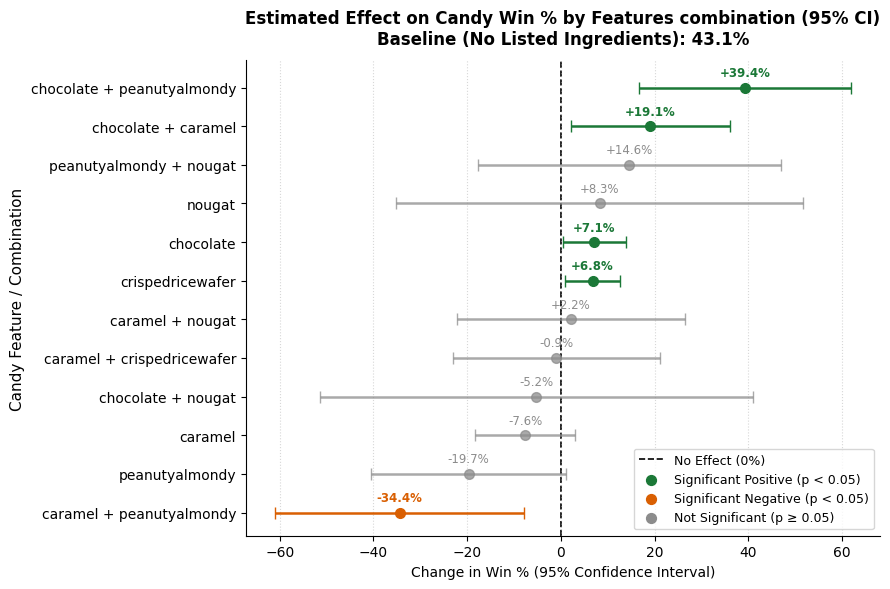

In [32]:
import matplotlib.pyplot as plt

# 1. Exclude Intercept (and duplicate row) so the x-axis focuses on effects
intercept_val = result_df.loc[result_df['Term'] == 'Intercept', 'Coef'].values.item()
# Removing intercept values and perfect collinearity
plot_df2 = result_df[~result_df['Term'].isin(['chocolate + crispedricewafer','Intercept'])].copy()

# Sort features by Coef
plot_df2 = plot_df2.sort_values('Coef').reset_index(drop=True)

# 2. Create forest plot
fig, ax = plt.subplots(figsize=(9, 6))

for idx, row in plot_df2.iterrows():
  lower_err = row['Coef'] - row['Conf interval low']
  upper_err = row['Conf interval upper'] - row['Coef']

  if row['P-Value'] < 0.05:
    color = '#1b7837' if row['Coef'] > 0 else '#d95f02'
    alpha = 1.0
    fontweight = 'bold'
  else:
    color = '#8c8c8c'
    alpha = 0.75
    fontweight = 'normal'

  ax.errorbar(
      row['Coef'],
      idx,
      xerr=[[lower_err], [upper_err]],
      fmt='o',
      color=color,
      markerfacecolor=color,
      capsize=4,
      markersize=7,
      linewidth=1.8,
      alpha=alpha,
  )

  ax.text(
      row['Coef'],
      idx + 0.22,
      f"{row['Coef']:+.1f}%",
      ha='center',
      va='bottom',
      fontsize=8.5,
      color=color,
      fontweight=fontweight,
  )

# 3. Reference line at zero
ax.axvline(
    x=0,
    color='black',
    linestyle='--',
    linewidth=1.2,
    zorder=1,
    label='No Effect (0%)',
)

# 4. Dummy scatter points for clean legend entries (avoids empty brackets)
ax.scatter([], [], color='#1b7837', s=50, label='Significant Positive (p < 0.05)')
ax.scatter([], [], color='#d95f02', s=50, label='Significant Negative (p < 0.05)')
ax.scatter([], [], color='#8c8c8c', s=50, label='Not Significant (p ≥ 0.05)')

# 5. Labels, ticks, and legend
ax.set_yticks(range(len(plot_df2)))
ax.set_yticklabels(plot_df2['Term'], fontsize=10)
ax.set_ylim(-0.6, len(plot_df2) - 0.3)

ax.set_title(
    'Estimated Effect on Candy Win % by Features combination (95% CI)\n'
    f'Baseline (No Listed Ingredients): {intercept_val:.1f}%',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
ax.set_xlabel('Change in Win % (95% Confidence Interval)', fontsize=10)
ax.set_ylabel('Candy Feature / Combination', fontsize=11)

ax.legend(loc='lower right', frameon=True, fontsize=9)
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


## Final Reccomendation

Go for Chocolate combined with nuts.

1. **Chocolate has a significant positive association** with the dependent variable. Its coefficient is +7.11.

2. **Crispedricewafer also has a significant positive association**, with a coefficient of +6.77.

3. **Chocolate and peanutyalmondy have a particularly strong positive interaction**, with a coefficient of +39.35. This suggests that combining these ingredients produces a substantially more positive outcome than their individual effects would suggest.

4. **Caramel and peanutyalmondy have a significant negative interaction**, with a coefficient of -34.43. This suggests that their combination is associated with a lower outcome.

5. Nougat does not appear to have a statistically significant effect in this model, either individually or in the interactions reported.


The multiple linear regression analysis reveals that chocolate and crisped rice wafer have statistically significant positive associations with the dependent variable, with coefficients of 7.11 (p = 0.038) and 6.77 (p = 0.025), respectively.

Furthermore, the interaction between chocolate and peanutyalmondy exhibits a strong positive and statistically significant coefficient of 39.35 (p < 0.001), suggesting a positive synergistic relationship between these two ingredients. Conversely, the interaction between caramel and peanutyalmondy has a significant negative coefficient of -34.43 (p = 0.012), indicating a potentially unfavorable combined effect. The interaction between chocolate and caramel is also positive and statistically significant (β = 19.08, p = 0.029).

Other ingredients and interaction terms do not exhibit statistically significant associations at the 5% significance level. Overall, the results suggest that the relationship between candy ingredients and the dependent variable depends not only on individual ingredients but also on their combinations.
